# 05 · Classical Machine Learning — TF-IDF + Linear Models
**Part of the [Sentiment Analysis on IMDB 50K](README.md) project.** Previous: [04 Preprocessing](04_text_preprocessing.ipynb).

Main agenda, part 1. We turn text into numbers (Bag-of-Words, TF-IDF), train and compare several classical models, tune the best, and dig into *why* it works and where it fails.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import time, os, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV, learning_curve
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression, SGDClassifier, RidgeClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB, ComplementNB, BernoulliNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_curve, precision_recall_curve, average_precision_score)
sns.set_theme(style='whitegrid')
df = pd.read_csv('data/imdb_clean.csv', usecols=['review','sentiment','label','clean'])
train_idx, test_idx = train_test_split(df.index, test_size=.2, stratify=df['label'], random_state=42)
Xtr_text, Xte_text = df.loc[train_idx,'clean'], df.loc[test_idx,'clean']
ytr, yte = df.loc[train_idx,'label'].values, df.loc[test_idx,'label'].values
print('train', len(ytr), 'test', len(yte), '| positive share', ytr.mean().round(3))

train 39665 test 9917 | positive share 0.502


## 1. Metrics we will use

Classes are balanced, so **accuracy** is fair; we also report precision, recall, F1 and ROC-AUC.

In [2]:
RESULTS = []
def evaluate(name, model, Xtr, Xte, train_time):
    pred = model.predict(Xte)
    score = model.decision_function(Xte) if hasattr(model,'decision_function') else model.predict_proba(Xte)[:,1]
    row = dict(model=name, accuracy=accuracy_score(yte,pred), precision=precision_score(yte,pred), recall=recall_score(yte,pred), f1=f1_score(yte,pred), roc_auc=roc_auc_score(yte,score), train_sec=train_time)
    RESULTS.append(row); return pd.Series({k:(v if isinstance(v,str) else round(float(v),4)) for k,v in row.items()})

## 2. Bag-of-Words (counts)

In [3]:
cv = CountVectorizer(max_features=50000, ngram_range=(1,1))
Xtr_bow = cv.fit_transform(Xtr_text); Xte_bow = cv.transform(Xte_text)
print(Xtr_bow.shape, 'sparsity: %.3f%% non-zero' % (Xtr_bow.nnz/np.prod(Xtr_bow.shape)*100))

(39665, 50000) sparsity: 0.268% non-zero


In [4]:
pd.DataFrame(Xtr_bow[:3, :12].toarray(), columns=cv.get_feature_names_out()[:12])

,aa,aag,aagh,aah,aahh,aaker,aaliyah,aames,aamir,aan,aand,aankhen
0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0


In [5]:
t=time.time(); nb_bow = MultinomialNB().fit(Xtr_bow, ytr); evaluate('MultinomialNB (BoW)', nb_bow, Xtr_bow, Xte_bow, time.time()-t)

model        MultinomialNB (BoW)
accuracy                  0.8496
precision                 0.8745
recall                    0.8176
f1                        0.8451
roc_auc                   0.9169
train_sec                 0.0298
dtype: object

In [6]:
t=time.time(); lr_bow = LogisticRegression(max_iter=2000, C=0.5).fit(Xtr_bow, ytr); evaluate('LogReg (BoW)', lr_bow, Xtr_bow, Xte_bow, time.time()-t)

model        LogReg (BoW)
accuracy            0.892
precision          0.8872
recall             0.8991
f1                 0.8931
roc_auc            0.9536
train_sec         29.9281
dtype: object

## 3. TF-IDF — weighting words by how informative they are

TF-IDF down-weights words that appear everywhere (*movie*, *film*) and up-weights distinctive ones. `sublinear_tf` replaces counts with 1+log(count).

In [7]:
tf1 = TfidfVectorizer(max_features=50000, sublinear_tf=True)
Xtr_t1 = tf1.fit_transform(Xtr_text); Xte_t1 = tf1.transform(Xte_text)
print(Xtr_t1.shape)

(39665, 50000)


In [8]:
idf = pd.Series(tf1.idf_, index=tf1.get_feature_names_out())
print('lowest IDF (most common):'); print(idf.sort_values().head(8).round(2)); print('highest IDF (rarest):'); print(idf.sort_values().tail(5).round(2))

lowest IDF (most common):
the     1.01
and     1.03
of      1.05
to      1.06
is      1.07
this    1.10
it      1.12
in      1.13
dtype: float64
highest IDF (rarest):
bugundian     10.9
bugundians    10.9
thersites     10.9
brunhild      10.9
brunhilda     10.9
dtype: float64


In [9]:
t=time.time(); lr1 = LogisticRegression(max_iter=2000, C=4).fit(Xtr_t1, ytr); evaluate('LogReg (TF-IDF 1-gram)', lr1, Xtr_t1, Xte_t1, time.time()-t)

model        LogReg (TF-IDF 1-gram)
accuracy                     0.9012
precision                    0.8952
recall                       0.9096
f1                           0.9023
roc_auc                      0.9646
train_sec                    2.4045
dtype: object

In [10]:
t=time.time(); sv1 = LinearSVC(C=0.5).fit(Xtr_t1, ytr); evaluate('LinearSVC (TF-IDF 1-gram)', sv1, Xtr_t1, Xte_t1, time.time()-t)

model        LinearSVC (TF-IDF 1-gram)
accuracy                        0.9005
precision                       0.8949
recall                          0.9084
f1                              0.9016
roc_auc                         0.9643
train_sec                       0.8364
dtype: object

## 4. TF-IDF with bigrams (1–2 grams)

In [11]:
t=time.time()
tf2 = TfidfVectorizer(max_features=200000, ngram_range=(1,2), sublinear_tf=True, min_df=2)
Xtr_t2 = tf2.fit_transform(Xtr_text); Xte_t2 = tf2.transform(Xte_text)
print(Xtr_t2.shape, f'{time.time()-t:.0f}s')

(39665, 200000) 28s


In [12]:
t=time.time(); lr2 = LogisticRegression(max_iter=2000, C=8).fit(Xtr_t2, ytr); evaluate('LogReg (TF-IDF 1-2gram)', lr2, Xtr_t2, Xte_t2, time.time()-t)

model        LogReg (TF-IDF 1-2gram)
accuracy                       0.916
precision                     0.9082
recall                        0.9263
f1                            0.9171
roc_auc                       0.9731
train_sec                     4.1598
dtype: object

In [13]:
t=time.time(); sv2 = LinearSVC(C=0.5).fit(Xtr_t2, ytr); evaluate('LinearSVC (TF-IDF 1-2gram)', sv2, Xtr_t2, Xte_t2, time.time()-t)

model        LinearSVC (TF-IDF 1-2gram)
accuracy                         0.9172
precision                          0.91
recall                           0.9267
f1                               0.9183
roc_auc                          0.9735
train_sec                        1.4068
dtype: object

In [14]:
t=time.time(); nb2 = MultinomialNB(alpha=0.3).fit(Xtr_t2, ytr); evaluate('MultinomialNB (TF-IDF 1-2gram)', nb2, Xtr_t2, Xte_t2, time.time()-t)

model        MultinomialNB (TF-IDF 1-2gram)
accuracy                              0.893
precision                            0.8941
recall                               0.8925
f1                                   0.8933
roc_auc                              0.9568
train_sec                            0.0692
dtype: object

In [15]:
t=time.time(); cnb2 = ComplementNB(alpha=0.3).fit(Xtr_t2, ytr); evaluate('ComplementNB (TF-IDF 1-2gram)', cnb2, Xtr_t2, Xte_t2, time.time()-t)

model        ComplementNB (TF-IDF 1-2gram)
accuracy                            0.8928
precision                           0.8944
recall                              0.8917
f1                                   0.893
roc_auc                             0.9568
train_sec                           0.0999
dtype: object

In [16]:
t=time.time(); bnb = BernoulliNB(alpha=0.5).fit((Xtr_t2>0).astype(int), ytr); evaluate('BernoulliNB (binary 1-2gram)', bnb, None, (Xte_t2>0).astype(int), time.time()-t)

model        BernoulliNB (binary 1-2gram)
accuracy                           0.8835
precision                          0.8813
recall                             0.8875
f1                                 0.8844
roc_auc                            0.9436
train_sec                          0.7725
dtype: object

In [17]:
t=time.time(); sgd = SGDClassifier(loss='modified_huber', alpha=2e-5, max_iter=30, random_state=42).fit(Xtr_t2, ytr); evaluate('SGD modified-huber (TF-IDF 1-2gram)', sgd, Xtr_t2, Xte_t2, time.time()-t)

model        SGD modified-huber (TF-IDF 1-2gram)
accuracy                                  0.9144
precision                                 0.9145
recall                                     0.915
f1                                        0.9147
roc_auc                                   0.9726
train_sec                                 0.4231
dtype: object

In [18]:
t=time.time(); rdg = RidgeClassifier(alpha=1.0, solver='sparse_cg').fit(Xtr_t2, ytr); evaluate('Ridge (TF-IDF 1-2gram)', rdg, Xtr_t2, Xte_t2, time.time()-t)

model        Ridge (TF-IDF 1-2gram)
accuracy                     0.9156
precision                    0.9094
recall                       0.9238
f1                           0.9166
roc_auc                      0.9728
train_sec                    2.1691
dtype: object

### 4.1 A tree ensemble for comparison

In [19]:
tf_rf = TfidfVectorizer(max_features=20000, sublinear_tf=True)
Xtr_rf = tf_rf.fit_transform(Xtr_text); Xte_rf = tf_rf.transform(Xte_text)
t=time.time(); rf = RandomForestClassifier(n_estimators=150, max_depth=None, n_jobs=-1, random_state=42).fit(Xtr_rf, ytr)
evaluate('RandomForest (TF-IDF 20k)', rf, Xtr_rf, Xte_rf, time.time()-t)

model        RandomForest (TF-IDF 20k)
accuracy                        0.8442
precision                       0.8412
recall                          0.8501
f1                              0.8456
roc_auc                         0.9246
train_sec                      96.1803
dtype: object

## 5. Model comparison

In [20]:
res = pd.DataFrame(RESULTS).set_index('model').sort_values('accuracy', ascending=False); res.round(4)

,accuracy,precision,recall,f1,roc_auc,train_sec
model,,,,,,
LinearSVC (TF-IDF 1-2gram),0.9172,0.9100,0.9267,0.9183,0.9735,1.4068
LogReg (TF-IDF 1-2gram),0.9160,0.9082,0.9263,0.9171,0.9731,4.1598
Ridge (TF-IDF 1-2gram),0.9156,0.9094,0.9238,0.9166,0.9728,2.1691
SGD modified-huber (TF-IDF 1-2gram),0.9144,0.9145,0.9150,0.9147,0.9726,0.4231
LogReg (TF-IDF 1-gram),0.9012,0.8952,0.9096,0.9023,0.9646,2.4045
LinearSVC (TF-IDF 1-gram),0.9005,0.8949,0.9084,0.9016,0.9643,0.8364
MultinomialNB (TF-IDF 1-2gram),0.8930,0.8941,0.8925,0.8933,0.9568,0.0692
ComplementNB (TF-IDF 1-2gram),0.8928,0.8944,0.8917,0.8930,0.9568,0.0999
LogReg (BoW),0.8920,0.8872,0.8991,0.8931,0.9536,29.9281


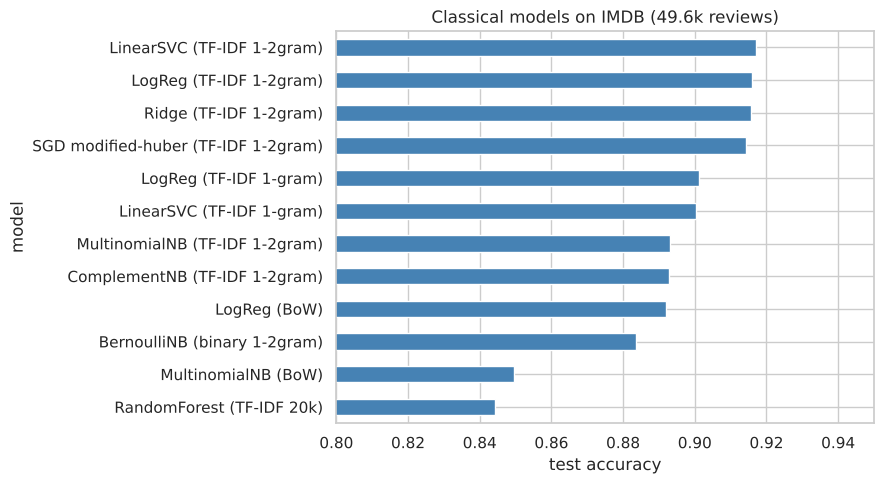

In [21]:
res['accuracy'].sort_values().plot(kind='barh', figsize=(9,5), color='steelblue'); plt.xlim(.8,.95); plt.xlabel('test accuracy'); plt.title('Classical models on IMDB (49.6k reviews)'); plt.tight_layout(); plt.show()

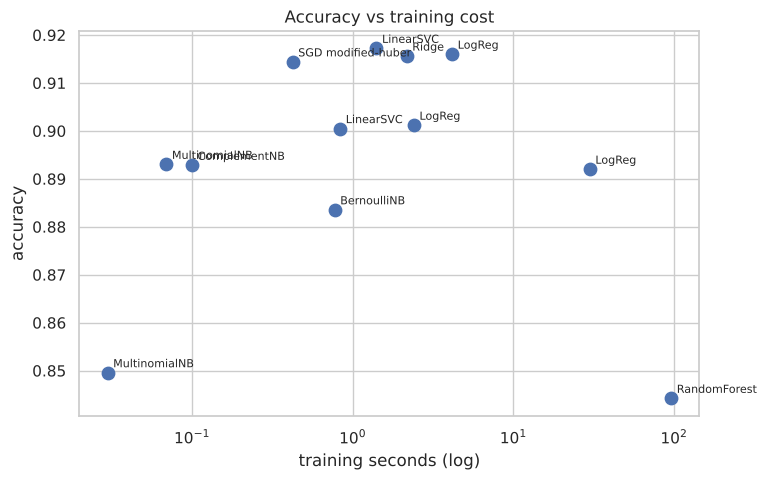

In [22]:
fig, ax = plt.subplots(figsize=(8,5)); ax.scatter(res['train_sec'], res['accuracy'], s=80)
for name,r in res.iterrows(): ax.annotate(name.split(' (')[0], (r.train_sec, r.accuracy), fontsize=8, xytext=(4,4), textcoords='offset points')
ax.set_xscale('log'); ax.set_xlabel('training seconds (log)'); ax.set_ylabel('accuracy'); ax.set_title('Accuracy vs training cost'); plt.show()

Observations: (1) TF-IDF > raw counts, (2) bigrams give a clear lift, (3) linear models (LR / SVM) beat Naive Bayes and Random Forest on sparse text. See the table above for exact numbers.

## 6. Cross-validation (is the test score a fluke?)

In [23]:
skf = StratifiedKFold(5, shuffle=True, random_state=42)
t=time.time()
cv_scores = cross_val_score(LinearSVC(C=0.5), Xtr_t2, ytr, cv=skf, scoring='accuracy', n_jobs=2)
print('LinearSVC 5-fold accuracy:', cv_scores.round(4), '| mean %.4f ± %.4f' % (cv_scores.mean(), cv_scores.std()), f'({time.time()-t:.0f}s)')

LinearSVC 5-fold accuracy: [0.9133 0.9152 0.9188 0.9125 0.9144] | mean 0.9148 ± 0.0022 (5s)


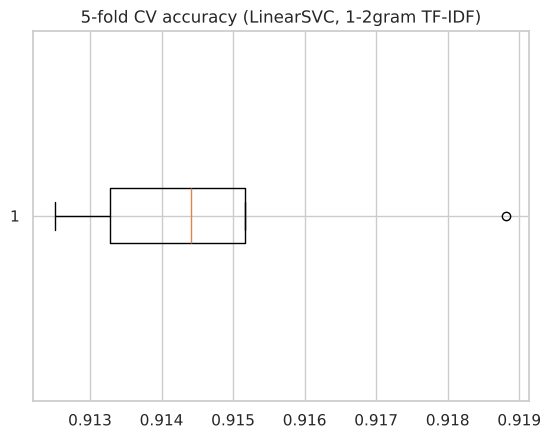

In [24]:
plt.boxplot(cv_scores, vert=False); plt.title('5-fold CV accuracy (LinearSVC, 1-2gram TF-IDF)'); plt.show()

## 7. Hyper-parameter tuning (GridSearchCV)

We tune the regularisation strength `C` of a linear SVM on the already-vectorised training data (3-fold).

In [25]:
grid = GridSearchCV(LinearSVC(), {'C':[0.05,0.1,0.25,0.5,1,2]}, cv=3, scoring='accuracy', n_jobs=2)
t=time.time(); grid.fit(Xtr_t2, ytr); print('best:', grid.best_params_, round(grid.best_score_,4), f'({time.time()-t:.0f}s)')

best: {'C': 0.5} 0.9118 (12s)


In [26]:
gs = pd.DataFrame(grid.cv_results_)[['param_C','mean_test_score','std_test_score']]; gs

,param_C,mean_test_score,std_test_score
0,0.05,0.894517,0.003048
1,0.10,0.903391,0.003636
2,0.25,0.909517,0.001803
3,0.50,0.911761,0.002033
4,1.00,0.910929,0.002481
5,2.00,0.909593,0.002930


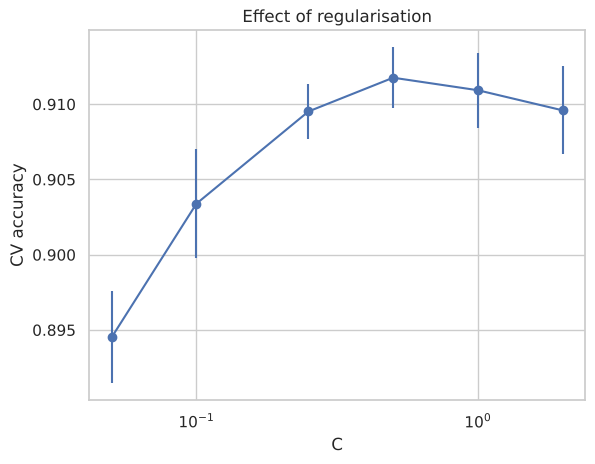

In [27]:
plt.errorbar(gs.param_C.astype(float), gs.mean_test_score, yerr=gs.std_test_score, marker='o'); plt.xscale('log'); plt.xlabel('C'); plt.ylabel('CV accuracy'); plt.title('Effect of regularisation'); plt.show()

In [28]:
grid_lr = GridSearchCV(LogisticRegression(max_iter=2000), {'C':[2,4,8,16,32]}, cv=3, scoring='accuracy', n_jobs=2)
t=time.time(); grid_lr.fit(Xtr_t2, ytr); print('best:', grid_lr.best_params_, round(grid_lr.best_score_,4), f'({time.time()-t:.0f}s)')

best: {'C': 32} 0.9107 (27s)


In [29]:
best_model = LogisticRegression(max_iter=2000, **grid_lr.best_params_).fit(Xtr_t2, ytr)
best_svm = LinearSVC(**grid.best_params_).fit(Xtr_t2, ytr)
for nm,m in [('Tuned LogReg',best_model),('Tuned LinearSVC',best_svm)]: print(nm, round(accuracy_score(yte, m.predict(Xte_t2)),4))

Tuned LogReg 0.9164
Tuned LinearSVC 0.9172


## 8. Final evaluation of the best classical model

In [30]:
final = best_model if accuracy_score(yte,best_model.predict(Xte_t2))>=accuracy_score(yte,best_svm.predict(Xte_t2)) else best_svm
name = type(final).__name__; pred = final.predict(Xte_t2); print('Final model:', name); print(classification_report(yte, pred, target_names=['negative','positive'], digits=4))

Final model: LinearSVC
              precision    recall  f1-score   support

    negative     0.9247    0.9077    0.9161      4940
    positive     0.9100    0.9267    0.9183      4977

    accuracy                         0.9172      9917
   macro avg     0.9174    0.9172    0.9172      9917
weighted avg     0.9173    0.9172    0.9172      9917



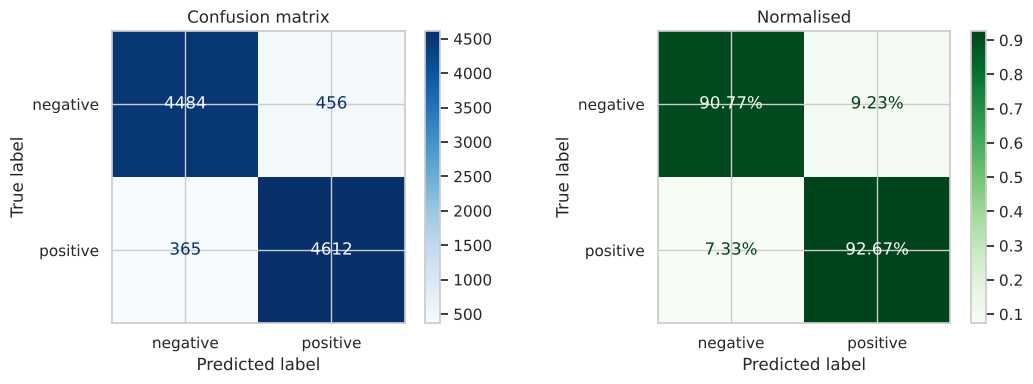

In [31]:
fig, ax = plt.subplots(1,2, figsize=(11,4))
ConfusionMatrixDisplay.from_predictions(yte, pred, display_labels=['negative','positive'], cmap='Blues', ax=ax[0]); ax[0].set_title('Confusion matrix')
ConfusionMatrixDisplay.from_predictions(yte, pred, display_labels=['negative','positive'], normalize='true', cmap='Greens', ax=ax[1], values_format='.2%'); ax[1].set_title('Normalised')
plt.tight_layout(); plt.show()

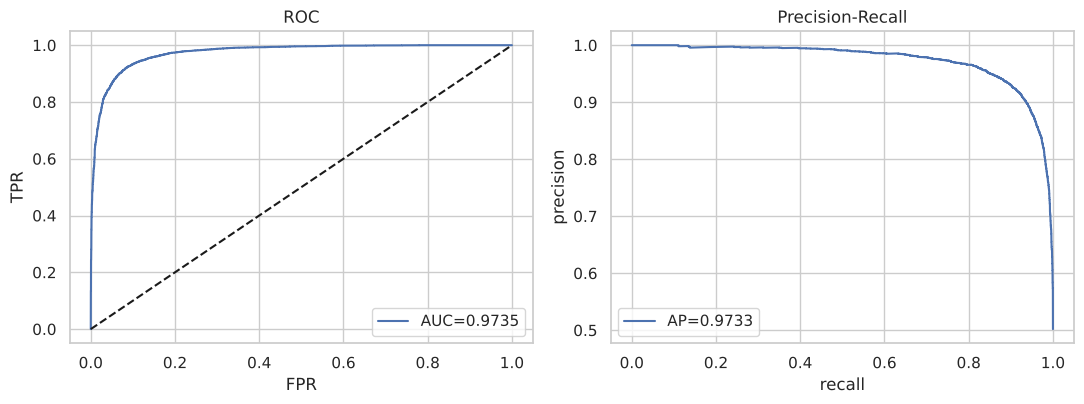

In [32]:
scores = final.decision_function(Xte_t2)
fpr,tpr,_ = roc_curve(yte, scores); prec,rec,_ = precision_recall_curve(yte, scores)
fig, ax = plt.subplots(1,2, figsize=(11,4.2))
ax[0].plot(fpr,tpr,label=f'AUC={roc_auc_score(yte,scores):.4f}'); ax[0].plot([0,1],[0,1],'k--'); ax[0].set_xlabel('FPR'); ax[0].set_ylabel('TPR'); ax[0].legend(); ax[0].set_title('ROC')
ax[1].plot(rec,prec,label=f'AP={average_precision_score(yte,scores):.4f}'); ax[1].set_xlabel('recall'); ax[1].set_ylabel('precision'); ax[1].legend(); ax[1].set_title('Precision-Recall')
plt.tight_layout(); plt.show()

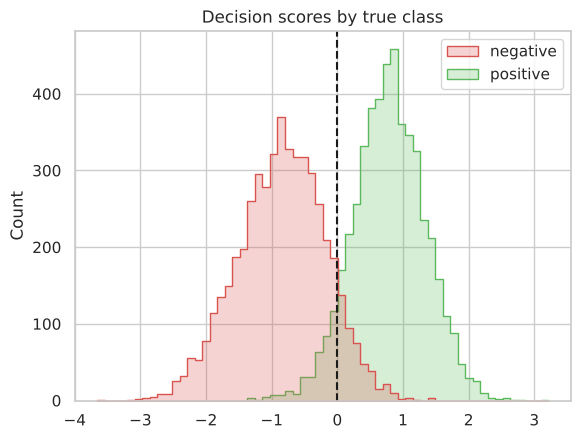

In [33]:
sns.histplot(x=scores, hue=np.where(yte==1,'positive','negative'), bins=60, palette={'negative':'#d9534f','positive':'#5cb85c'}, element='step'); plt.axvline(0,color='k',ls='--'); plt.title('Decision scores by true class'); plt.show()

## 9. Why does it work? — the model's learned vocabulary

In [34]:
coef = pd.Series(best_model.coef_[0], index=tf2.get_feature_names_out()).sort_values()
print('TOP NEGATIVE:', ', '.join(coef.head(25).index)); print(); print('TOP POSITIVE:', ', '.join(coef.tail(25).index[::-1]))

TOP NEGATIVE: awful, worst, boring, the worst, waste, poor, terrible, bad, horrible, dull, poorly, disappointment, not even, worse, annoying, disappointing, lame, fails, not funny, stupid, waste of, nothing, not very, forgettable, not worth

TOP POSITIVE: excellent, perfect, great, amazing, wonderful, brilliant, hilarious, superb, today, enjoyable, loved, surprised, must see, watch it, awesome, strong, gem, incredible, fantastic, subtle, enjoyed, especially, well worth, highly, solid


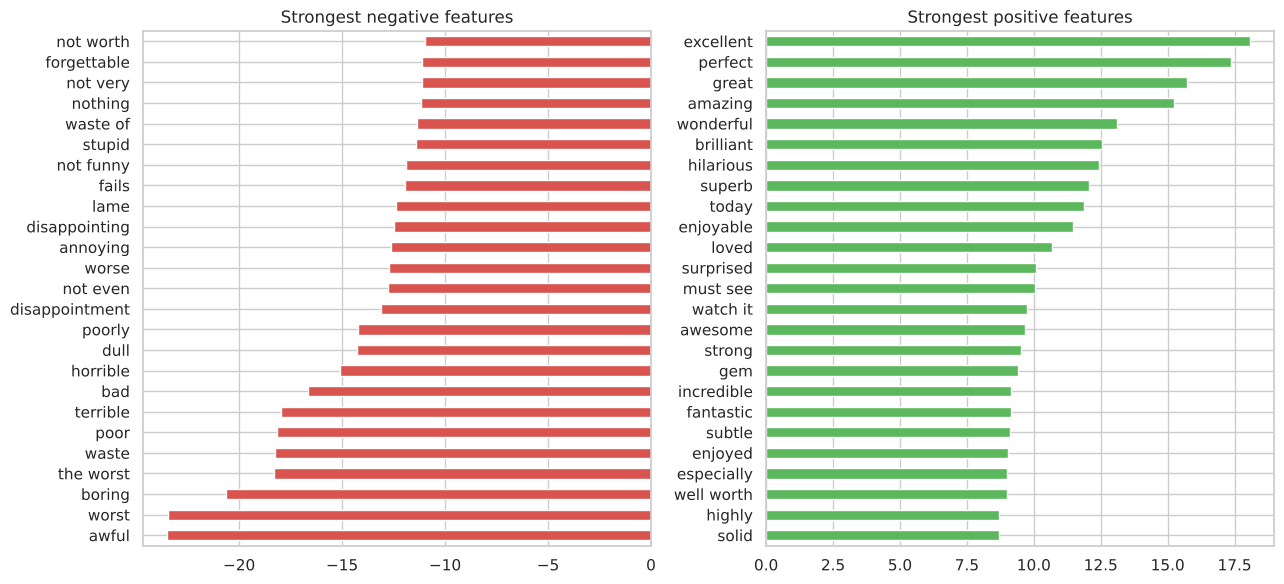

In [35]:
fig, ax = plt.subplots(1,2, figsize=(13,6))
coef.head(25).plot(kind='barh', color='#d9534f', ax=ax[0]); ax[0].set_title('Strongest negative features')
coef.tail(25).plot(kind='barh', color='#5cb85c', ax=ax[1]); ax[1].set_title('Strongest positive features')
plt.tight_layout(); plt.show()

In [36]:
bi = coef[coef.index.str.contains(' ')]; print('Top bigrams  neg:', list(bi.head(12).index)); print('Top bigrams  pos:', list(bi.tail(12).index[::-1]))

Top bigrams  neg: ['the worst', 'not even', 'not funny', 'waste of', 'not very', 'not worth', 'not recommend', 'at best', 'at all', 'not good', 'worst movie', 'just not']
Top bigrams  pos: ['must see', 'watch it', 'well worth', 'this is', 'better than', 'loved this', 'the best', 'is must', 'some of', 'highly recommend', 'very good', 'is good']


## 10. Explaining a single prediction

In [37]:
def explain(text, k=8):
    v = tf2.transform([text]); contrib = v.multiply(best_model.coef_[0]).tocoo()
    names = tf2.get_feature_names_out()
    items = sorted([(names[j], c) for j,c in zip(contrib.col, contrib.data)], key=lambda x: x[1])
    p = best_model.predict_proba(v)[0,1]
    print(f'P(positive) = {p:.3f}'); print('  pushes NEGATIVE:', [(w, round(c,2)) for w,c in items[:k]]); print('  pushes POSITIVE:', [(w, round(c,2)) for w,c in items[-k:][::-1]])
explain('this movie was a complete waste of time but the acting was good')

P(positive) = 0.000
  pushes NEGATIVE: [('waste', np.float64(-4.12)), ('waste of', np.float64(-3.0)), ('of time', np.float64(-1.18)), ('complete waste', np.float64(-0.81)), ('acting', np.float64(-0.72)), ('was', np.float64(-0.7)), ('complete', np.float64(-0.62)), ('time but', np.float64(-0.49))]
  pushes POSITIVE: [('was good', np.float64(1.5)), ('good', np.float64(0.39)), ('time', np.float64(0.24)), ('this movie', np.float64(0.23)), ('the acting', np.float64(0.21)), ('acting was', np.float64(0.01)), ('but', np.float64(0.01)), ('but the', np.float64(-0.1))]


In [38]:
explain('an absolute masterpiece, i loved every minute of it')

P(positive) = 0.990
  pushes NEGATIVE: [('every', np.float64(-0.47)), ('of it', np.float64(-0.2)), ('minute', np.float64(-0.2)), ('of', np.float64(-0.19)), ('an', np.float64(-0.06)), ('absolute', np.float64(0.01)), ('absolute masterpiece', np.float64(0.04)), ('it', np.float64(0.05))]
  pushes POSITIVE: [('loved', np.float64(2.13)), ('masterpiece', np.float64(1.66)), ('every minute', np.float64(0.58)), ('minute of', np.float64(0.43)), ('an absolute', np.float64(0.4)), ('loved every', np.float64(0.26)), ('it', np.float64(0.05)), ('absolute masterpiece', np.float64(0.04))]


## 11. Error analysis

In [39]:
test_df = df.loc[test_idx].copy(); test_df['pred']=pred; test_df['score']=scores; test_df['correct']=test_df.pred==test_df.label
print('errors:', (~test_df.correct).sum(), 'of', len(test_df))

errors: 821 of 9917


In [40]:
print('False positives (predicted pos, truly neg):', ((test_df.pred==1)&(test_df.label==0)).sum()); print('False negatives:', ((test_df.pred==0)&(test_df.label==1)).sum())

False positives (predicted pos, truly neg): 456
False negatives: 365


In [41]:
worst = test_df[~test_df.correct].assign(abs_score=lambda d: d.score.abs()).sort_values('abs_score', ascending=False).head(4)
for _,r in worst.iterrows(): print(f"TRUE={r.sentiment} score={r.score:.2f}\n{r.review[:450]}\n{'-'*70}")

TRUE=negative score=1.45
this one of the best celebrity's reality shows a ever saw. we can see the concerts we can see the life of Britney, i love the five episodes. i was always being surprised by Britney and the subjects of the show i think that some people don't watch the show at all we can how a great person she his. she his really funny really gentle and she loves her fans and we can see how she loves her work. i just don't give a 10 because of k-fed he his a real j
----------------------------------------------------------------------
TRUE=negative score=1.38
When i finally had the opportunity to watch Zombie 3(Zombie Flesheaters 2 in Europe)on an import Region 2 Japanese dvd,i was blown away by just how entertaining this zombie epic is.The transfer is just about immaculate,as good as it's ever going to look unless Anchor Bay gets a hold of it.The gore truly stands out like it should and you can really appreciate the excellent makeup and gore fx.The sound is also terrific.It's on

Typical mistakes: sarcasm, reviews that praise the *book/original* before trashing the film, and reviews that summarise a dark plot with negative words while liking the movie.

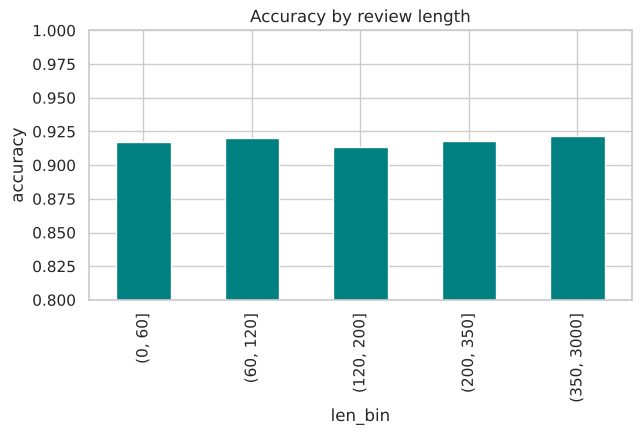

In [42]:
test_df['n_words']=test_df['clean'].str.split().str.len()
test_df['len_bin']=pd.cut(test_df.n_words,[0,60,120,200,350,3000])
test_df.groupby('len_bin')['correct'].mean().round(4).plot(kind='bar', color='teal', figsize=(7,3.5)); plt.ylim(.8,1); plt.ylabel('accuracy'); plt.title('Accuracy by review length'); plt.show()

In [43]:
test_df['conf']=pd.cut(test_df.score.abs(),[0,.25,.5,1,2,10]); test_df.groupby('conf')['correct'].agg(['mean','count']).round(4)

,mean,count
conf,,
"(0.0, 0.25]",0.6455,1337
"(0.25, 0.5]",0.8630,1504
"(0.5, 1.0]",0.9631,3412
"(1.0, 2.0]",0.9956,3380
"(2.0, 10.0]",1.0000,284


## 12. Learning curve — would more data help?

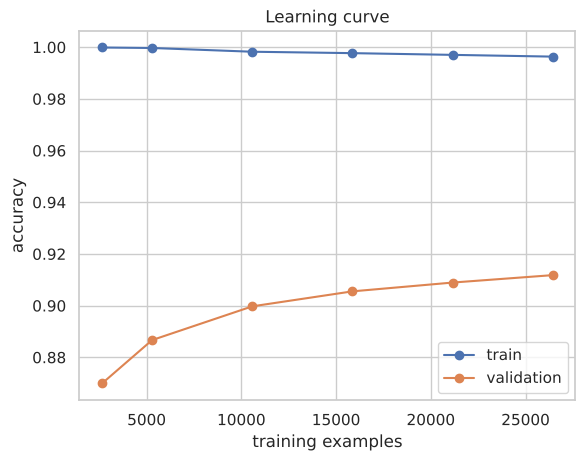

In [44]:
sizes, tr_s, va_s = learning_curve(LinearSVC(C=grid.best_params_['C']), Xtr_t2, ytr, train_sizes=[.1,.2,.4,.6,.8,1.0], cv=3, n_jobs=2)
plt.plot(sizes, tr_s.mean(1), 'o-', label='train'); plt.plot(sizes, va_s.mean(1), 'o-', label='validation'); plt.xlabel('training examples'); plt.ylabel('accuracy'); plt.legend(); plt.title('Learning curve'); plt.show()

## 13. Threshold analysis

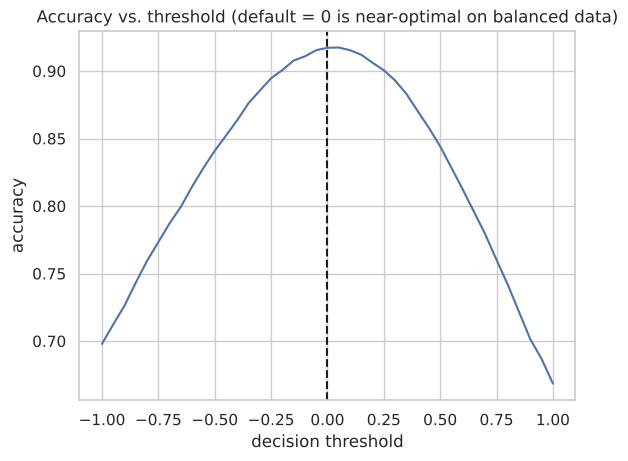

best threshold 0.05 acc 0.9174


In [45]:
ths = np.linspace(-1,1,41); accs=[accuracy_score(yte, (scores>t).astype(int)) for t in ths]
plt.plot(ths, accs); plt.axvline(0,color='k',ls='--'); plt.xlabel('decision threshold'); plt.ylabel('accuracy'); plt.title('Accuracy vs. threshold (default = 0 is near-optimal on balanced data)'); plt.show()
print('best threshold', ths[int(np.argmax(accs))].round(2), 'acc', round(max(accs),4))

## 14. Build one reusable Pipeline and test on new text

In [46]:
pipe = Pipeline([('tfidf', TfidfVectorizer(max_features=200000, ngram_range=(1,2), sublinear_tf=True, min_df=2)), ('clf', LogisticRegression(max_iter=2000, **grid_lr.best_params_))])
t=time.time(); pipe.fit(Xtr_text, ytr); print('pipeline accuracy:', round(pipe.score(Xte_text, yte),4), f'({time.time()-t:.0f}s)')

pipeline accuracy: 0.9164 (33s)


In [47]:
import re
def predict(text):
    c = re.sub(r'\s+',' ', re.sub(r'[^a-z\s]',' ', re.sub(r'<[^>]+>',' ', text.lower().replace("n't",' not')))).strip()
    p = pipe.predict_proba([c])[0,1]; return ('positive' if p>.5 else 'negative', round(p,3))
for s in ['Absolutely fantastic film, the best I have seen this year!','Boring, predictable and far too long. Waste of money.','It was not good.','Not bad at all, quite enjoyable','The plot was thin but the performances saved it']: print(f'{predict(s)}  ←  {s}')

('positive', np.float64(0.999))  ←  Absolutely fantastic film, the best I have seen this year!
('negative', np.float64(0.0))  ←  Boring, predictable and far too long. Waste of money.
('negative', np.float64(0.0))  ←  It was not good.
('positive', np.float64(0.905))  ←  Not bad at all, quite enjoyable
('negative', np.float64(0.242))  ←  The plot was thin but the performances saved it


In [48]:
os.makedirs('models', exist_ok=True); joblib.dump(pipe, 'models/tfidf_logreg_pipeline.pkl', compress=3); print(round(os.path.getsize('models/tfidf_logreg_pipeline.pkl')/1e6,1),'MB')

4.1 MB


In [49]:
res.to_csv('data/classical_results.csv'); pd.Series({'best_classical_accuracy': float(res.accuracy.max()), 'best_model': res.accuracy.idxmax()}).to_frame('value')

,value
best_classical_accuracy,0.917213
best_model,LinearSVC (TF-IDF 1-2gram)


## 15. Summary
- Best classical models are **linear classifiers on TF-IDF 1–2-grams**, ≈ 91% accuracy (exact numbers in the table in §5/§8).
- Bigrams and TF-IDF weighting help more than any amount of text cleaning.
- Naive Bayes is fastest; Random Forest is the weakest on sparse text.
- Remaining errors are sarcasm, mixed opinions and plot-summary reviews — these need *context*, which motivates deep learning.

**Next:** [06 – Deep learning (PyTorch)](06_deep_learning_pytorch.ipynb)